# La diversification résiste-t-elle aux baisses de marché ?

**Projet Python ENSAE — Rapport final**

## Résumé

On compare sept portefeuilles de juin 2007 à décembre 2025. Sur les sept cycles de baisse retenus, les cinq allocations qui associent actions et autres classes d'actifs perdent moins que SPY, mais restent perdantes. Ajouter des pays protège de façon plus irrégulière. Le témoin à rendement nul montre qu'une partie de la protection vient simplement d'une moindre part d'actions. L'apport des obligations varie selon les crises : en 2022, la trésorerie fait mieux que les obligations étudiées.

## 1. Introduction : que signifie « résister » ?

En 2008, les obligations progressent pendant que les actions chutent ; en 2022, les deux baissent. On cherche donc à savoir si une protection observée dans une crise se retrouve dans les autres. On distingue pour cela **perdre moins que la référence** et **préserver son capital pendant la baisse**.

Notre référence est SPY, un fonds représentant les grandes actions américaines. On regarde ce que changent l'ajout d'autres pays, puis celui d'obligations, d'or ou de trésorerie, avec des allocations fixées pour toute la période. Les sorties du notebook sont enregistrées pour permettre une lecture directe.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display

# on repère le dossier du projet
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "fonctions").is_dir())
sys.path.insert(0, str(ROOT))

from fonctions.scraping import TICKERS, fetch_yahoo, fetch_fred
from fonctions.audit import auditer_prix, tracer_base_100, auditer_cpi
from fonctions.analyse import (
    ALLOCATIONS, simuler_allocations, capital_et_recul, indicateurs,
    pertes_en_baisse, reperer_episodes, rendements_episodes,
    contexte_inflation, comparer_decennies, comparer_seuils, comparer_temoin,
)
from fonctions.graphiques import (
    tracer_capital, tracer_reculs, tracer_episodes, tracer_correlations,
)

## 2. Données et préparation

On utilise sept **ETF**, des fonds dont les parts s'échangent en bourse. SPY représente les grandes actions américaines, EFA les actions développées hors États-Unis et Canada, EEM les actions émergentes et GLD l'or. IEF et SHY détiennent des obligations de l'État américain de durées restantes **7–10 ans** et **1–3 ans**. BIL détient des bons du Trésor américain à **1–3 mois** : on l'utilise pour représenter une trésorerie rémunérée, dont le capital n'est toutefois pas garanti.

Une action représente une part d'entreprise, une obligation une dette. Les fonds obligataires et BIL reçoivent des intérêts, alors que l'or ne procure pas ce revenu. L'historique commun commence le **1er juin 2007**, après le lancement de BIL, et s'arrête le **31 décembre 2025**, soit environ 18,5 ans.

On télécharge les cours de **Yahoo Finance avec yfinance**. Les cours ajustés tiennent compte des distributions et divisions d'actions ; on ne rajoute donc pas les distributions aux rendements. Pour l'inflation, on utilise l'indice américain **CPIAUCSL**, diffusé par **FRED**, dès juin 2006 pour disposer d'un an de recul au début de l'étude.

Les deux tableaux sont sauvegardés en Parquet dans `data/raw/`. Le notebook les lit s'ils existent et appelle les fonctions de collecte sinon. On peut ainsi retrouver les résultats sans dépendre d'un nouveau téléchargement. La collecte FRED par `fetch_fred()` nécessite une clé personnelle dans `.env` ; les fichiers fournis et leur provenance sont décrits dans le README.

In [2]:
chemin_prix = ROOT / "data/raw/asset_prices.parquet"
chemin_cpi = ROOT / "data/raw/CPIAUCSL.parquet"

prix_bruts = pd.read_parquet(chemin_prix) if chemin_prix.is_file() else fetch_yahoo()
inflation = pd.read_parquet(chemin_cpi) if chemin_cpi.is_file() else fetch_fred()

### Mettre les séries sur un calendrier commun

On garde la période étudiée et les dates où les sept prix sont disponibles. On ne remplace pas un prix manquant par le précédent, ce qui créerait artificiellement un rendement nul. L'audit vérifie ensuite l'ordre des dates, les doublons et les prix manquants ou non positifs. Tous les cours sont exprimés en dollars.

,première date,dernière date,séances,manquants,prix <= 0
Ticker,,,,,
SPY,2007-06-01,2025-12-31,4677,0,0
IEF,2007-06-01,2025-12-31,4677,0,0
SHY,2007-06-01,2025-12-31,4677,0,0
GLD,2007-06-01,2025-12-31,4677,0,0
BIL,2007-06-01,2025-12-31,4677,0,0
EFA,2007-06-01,2025-12-31,4677,0,0
EEM,2007-06-01,2025-12-31,4677,0,0


4677 dates communes, soit 4676 rendements quotidiens
0 dates retirées


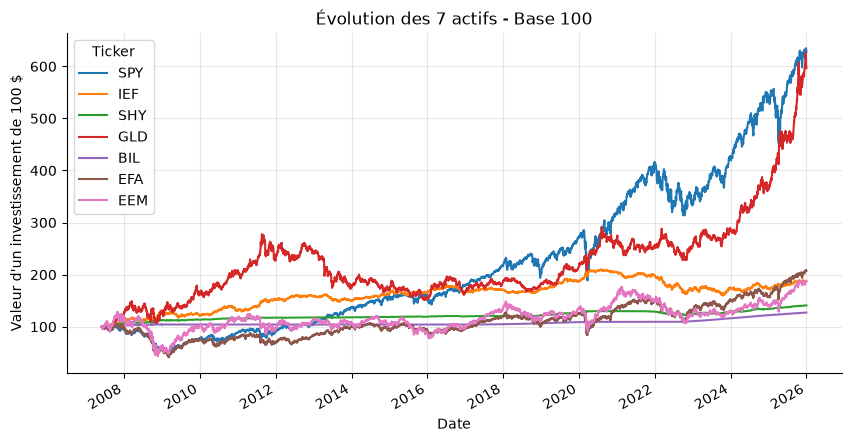

In [3]:
prix = prix_bruts.loc["2007-06-01":"2025-12-31", list(TICKERS)].dropna()
display(auditer_prix(prix))
print(f"{len(prix)} dates communes, soit {len(prix) - 1} rendements quotidiens")
print(f"{len(prix_bruts.loc['2007-06-01':'2025-12-31']) - len(prix)} dates retirées")
tracer_base_100(prix)

On obtient **4 677 dates communes**, sans retirer de séance, soit **4 676 rendements quotidiens**. Le graphique montre déjà des parcours différents : BIL évolue peu à court terme, les actions subissent des chutes marquées et l'or suit une trajectoire distincte. La suite étudie ce qui se passe quand on combine ces actifs.

### Passer du niveau des prix à l'inflation

L'inflation annuelle mesure la variation de l'indice par rapport au même mois un an avant. Une valeur de 3 % signifie que les prix ont augmenté de 3 % en douze mois. On garde un calendrier mensuel complet avant ce calcul pour que le décalage de douze observations corresponde bien à douze mois.

Dans la collecte fournie, **octobre 2025 est manquant**. On ne l'estime pas : ce mois est exclu de la comparaison selon l'inflation, mais les rendements de marché correspondants restent dans les autres analyses. L'inflation décrit le contexte ; elle ne sert ni à corriger les rendements ni à choisir les allocations.

In [4]:
inflation = inflation.reindex(pd.date_range("2006-06-01", "2025-12-01", freq="MS"))
display(auditer_cpi(inflation))
print("Mois sans indice :", inflation.index[inflation["CPIAUCSL"].isna()].strftime("%Y-%m").tolist())

,première date,dernière date,nombre de lignes,cases nulles
0,2006-06-01,2025-12-01,235,1


Mois sans indice : ['2025-10']


## 3. Méthode : allocations, rééquilibrage et indicateurs

On fixe les **poids cibles**, c'est-à-dire la part du capital placée dans chaque actif. US 60/40 signifie 60 % en SPY et 40 % en IEF. Pour les actions monde, on choisit 60 % SPY, 25 % EFA et 15 % EEM : les États-Unis restent majoritaires, sans reproduire exactement un indice mondial.

Chaque comparaison répond à une question :

| Comparaison | Question |
|---|---|
| Actions monde / Actions US | Ajouter des pays réduit-il les pertes ? |
| US 60/40 / Actions US | Que change l'ajout d'obligations ? |
| Monde 60/40 / Actions monde | Retrouve-t-on cet effet avec des actions internationales ? |
| US 50/30/20 / US 60/40 | Que change l'ajout d'or avec une moindre part actions ? |
| US 60/40 / US 60/40 court / US 60/40 cash | À même cible actions, quel rôle joue la durée des titres obligataires ? |

Le 50/30/20 change à la fois les parts actions, obligations et or : on ne pourra pas attribuer son résultat au seul or. « Cash » désigne ici BIL, pas des espèces à rendement nul.

In [5]:
poids_cibles = pd.DataFrame(ALLOCATIONS).T.fillna(0)
display((100 * poids_cibles).round(0).rename_axis("poids cibles (%)"))

,SPY,EFA,EEM,IEF,GLD,SHY,BIL
poids cibles (%),,,,,,,
Actions US,100.0,0.0,0.0,0.0,0.0,0.0,0.0
Actions monde,60.0,25.0,15.0,0.0,0.0,0.0,0.0
US 60/40,60.0,0.0,0.0,40.0,0.0,0.0,0.0
Monde 60/40,36.0,15.0,9.0,40.0,0.0,0.0,0.0
US 50/30/20,50.0,0.0,0.0,30.0,20.0,0.0,0.0
US 60/40 court,60.0,0.0,0.0,0.0,0.0,40.0,0.0
US 60/40 cash,60.0,0.0,0.0,0.0,0.0,0.0,40.0


### Suivre la valeur des portefeuilles

On investit au début de juin 2007, sans apport ni retrait. On revient aux poids cibles à la dernière clôture de chaque mois, avant le rendement de la première séance du mois suivant. Entre deux rééquilibrages, les poids évoluent avec les cours.

Par exemple, un capital de 100 réparti entre 60 d'actions et 40 d'un autre actif devient 66 et 40 si les actions gagnent 10 % et que le reste ne bouge pas. Les actions représentent alors **62,26 %** du total. Pour revenir à 60/40, on répartit les 106 atteints selon cette cible : on conserve le gain.

On applique cette même règle sur toute la période, sans l'adapter aux crises. Les frais internes des fonds sont reflétés dans les cours ; on ne simule ni les impôts ni les frais de courtage.

On suit trois indicateurs : le **rendement annualisé**, taux annuel constant donnant le même capital final ; la **volatilité annualisée**, qui mesure l'ampleur des fluctuations avec la convention de 252 séances par an ; et le **recul maximal**, la plus forte perte depuis un sommet antérieur. Passer de 100 à 80 correspond ainsi à un recul de 20 %.

In [6]:
rendements = simuler_allocations(prix)
capital, recul = capital_et_recul(rendements, prix.index[0])

## 4. Résultats : performance globale, jours de baisse et cycles

In [7]:
synthese = indicateurs(rendements, capital, recul)
display(synthese.round(2))

,rendement annualisé (%),volatilité annualisée (%),recul maximal (%)
Actions US,10.38,19.91,-55.19
Actions monde,7.87,20.70,-57.22
US 60/40,7.95,11.13,-32.58
Monde 60/40,6.48,11.55,-34.66
US 50/30/20,8.79,10.24,-27.00
US 60/40 court,7.22,11.57,-35.29
US 60/40 cash,6.98,11.69,-36.85


### Croissance et fluctuations sur 2007–2025

SPY atteint **10,38 %** de rendement annualisé, contre **7,87 %** pour les actions monde. Ces dernières fluctuent même un peu plus : leur volatilité est de **20,70 %**, contre **19,91 %** pour SPY. Avec ces poids et sur cette période, ajouter des pays n'améliore donc ni la croissance finale ni les fluctuations.

Le US 60/40 atteint **7,95 %** de rendement pour **11,13 %** de volatilité ; le US 50/30/20, **8,79 %** et **10,24 %**. Le US 60/40 cash rapporte **6,98 %**, avec une volatilité de **11,69 %**. Les allocations mixtes fluctuent moins que SPY, mais leur croissance est inférieure. On doit encore regarder les pertes traversées.

Le graphique part de 100 pour chaque portefeuille. L'échelle est logarithmique : les doublements de 100 à 200 et de 200 à 400 occupent la même hauteur.

*Source des graphiques : Yahoo Finance, cours ajustés ; calculs du projet sur juin 2007–décembre 2025.*

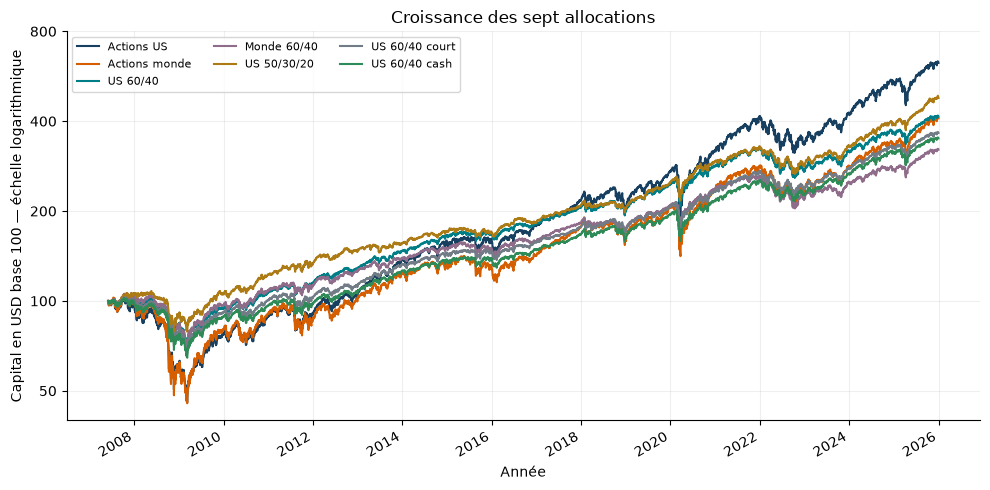

In [8]:
tracer_capital(capital)

La croissance finale masque les chutes intermédiaires. On regarde donc l'écart au **meilleur niveau déjà atteint par chaque portefeuille**. Zéro correspond à un sommet ; −20 % signifie que le capital est 20 % en dessous. Revenir à zéro signifie avoir récupéré ce sommet.

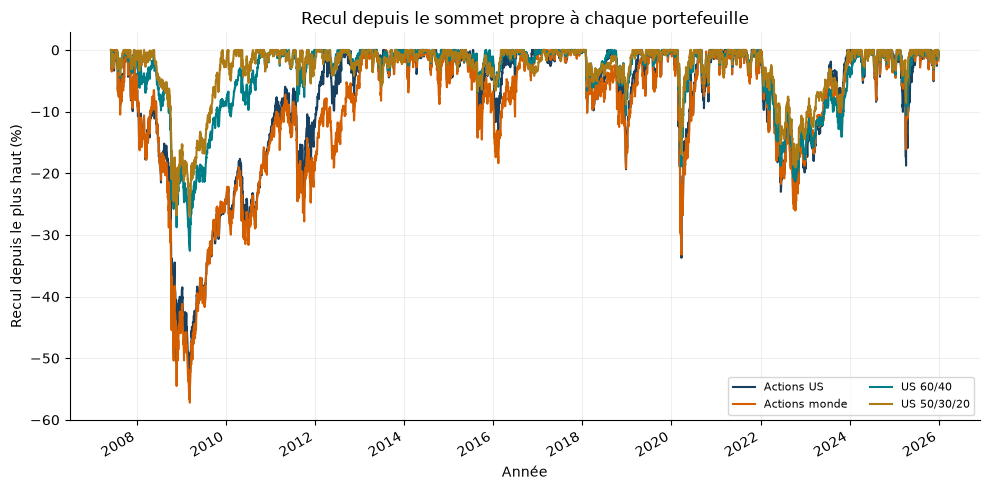

In [9]:
tracer_reculs(recul)

Le recul maximal de SPY atteint **−55,19 %** : un capital de 100 au sommet ne vaut plus que **44,81** au creux. On trouve **−32,58 %** pour le US 60/40, **−27,00 %** pour le US 50/30/20 et **−36,85 %** pour le US 60/40 cash. Les actions monde atteignent **−57,22 %**. Les pertes restent donc importantes, y compris avec plusieurs classes d'actifs.

Chaque recul part du sommet propre au portefeuille, pas forcément de l'investissement initial. On affiche quatre courbes pour la lisibilité ; le tableau couvre les sept allocations.

### Que se passe-t-il quand SPY baisse ?

#### Les séances négatives

On compare les mêmes dates, celles où SPY baisse. On mesure le rendement moyen et les proportions de séances où chaque allocation fait **strictement mieux que SPY** ou reste **sans perte**. Ces fréquences décrivent l'historique ; elles ne permettent pas de prévoir les prochaines baisses.

In [10]:
print(f"{(rendements['Actions US'] < 0).sum()} séances où SPY baisse")
display(pertes_en_baisse(rendements).round(2))

2091 séances où SPY baisse


,rendement moyen (%),mieux que SPY (%),sans perte (%)
Actions US,-0.85,0.00,0.00
Actions monde,-0.86,48.49,9.09
US 60/40,-0.46,86.66,11.96
Monde 60/40,-0.47,82.11,14.78
US 50/30/20,-0.39,83.98,19.03
US 60/40 court,-0.50,96.84,2.53
US 60/40 cash,-0.50,99.43,0.77


Sur les **2 091 séances négatives** de SPY, sa perte moyenne est de **−0,85 %**, contre **−0,46 %** pour le US 60/40 et **−0,39 %** pour le US 50/30/20. Le 60/40 fait mieux que SPY dans **86,66 %** des cas, mais reste sans perte dans seulement **11,96 %**. On observe une atténuation fréquente, pas une protection complète.

Le US 60/40 cash perd en moyenne **0,50 %** et fait mieux que SPY dans **99,43 %** des séances sélectionnées, mais il évite la perte dans seulement **0,77 %** des cas. Les actions monde perdent en moyenne **0,86 %**. Sélectionner les jours de baisse de SPY favorise les allocations moins exposées à cet actif : le témoin de la partie 5 aide à préciser cet effet.

#### Les cycles de baisse

Une séance ne décrit pas une longue baisse. On suit donc SPY depuis son dernier sommet jusqu'à son premier retour à ce niveau, en retenant les cycles dont le recul atteint **10 %**. Le creux est le minimum de SPY dans le cycle.

On compare les rendements **du sommet au creux de SPY, aux mêmes dates pour tous**. Ce calcul diffère du recul maximal propre à chaque allocation, dont le sommet ou le creux peuvent survenir ailleurs.

In [11]:
episodes = reperer_episodes(capital["Actions US"])
performance_episodes = rendements_episodes(capital, episodes)
display(episodes)

,sommet,creux,recuperation
0,2007-10-09,2009-03-09,2012-08-16
1,2015-07-20,2016-02-11,2016-04-18
2,2018-01-26,2018-02-08,2018-08-06
3,2018-09-20,2018-12-24,2019-04-12
4,2020-02-19,2020-03-23,2020-08-10
5,2022-01-03,2022-10-12,2023-12-13
6,2025-02-19,2025-04-08,2025-06-26


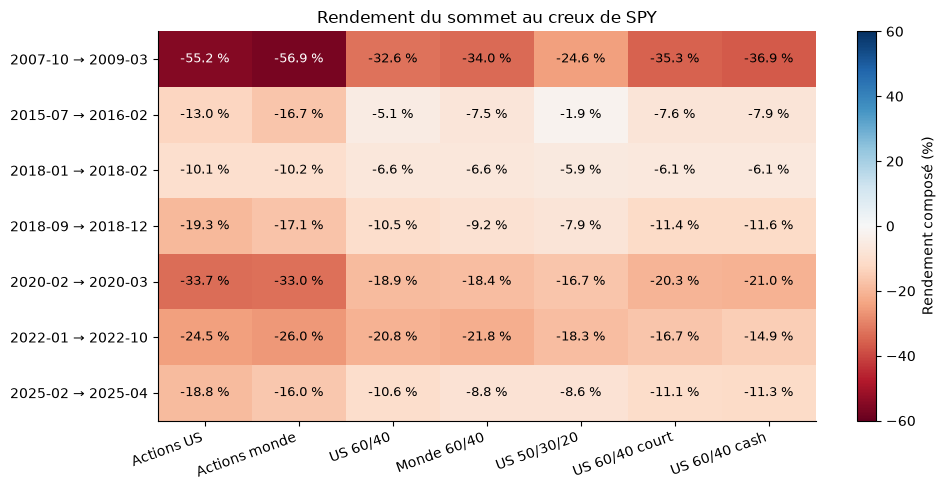

In [12]:
tracer_episodes(performance_episodes, episodes)

Les cinq allocations qui combinent plusieurs classes d'actifs perdent moins que SPY dans **7 cycles sur 7**, mais restent négatives. Les actions monde font mieux dans **3 cas sur 7**. Une case plus claire indique donc une perte moins forte, pas forcément un gain.

En 2007–2009, SPY perd **55,19 %**, le US 60/40 **32,57 %** et le US 60/40 cash **36,85 %**. En 2022, le classement change : le 60/40 perd **20,77 %**, contre **16,67 %** pour sa version courte et **14,89 %** pour sa version cash. La durée des titres détenus compte donc dans cette crise.

Les sept cycles sont récupérés à fin 2025. La règle regroupe les rechutes avant récupération : les corrections de 2010 et 2011 restent dans le cycle 2007–2012. On ne recense pas séparément toutes les corrections historiques.

## 5. Approfondissement : rôle des autres actifs et contexte d'inflation

### Un témoin à même part actions cible

Quelle part de la protection vient simplement de détenir moins d'actions ? Si SPY perd 10 % sur une séance commencée aux poids cibles et que le reste ne bouge pas, une allocation 60/40 perd 6 %, sans qu'un autre actif ait gagné.

On construit donc un **témoin théorique : 60 % SPY et 40 % laissés en liquide à 0 %**, avec le même rééquilibrage mensuel. Il se distingue de BIL, qui représente une trésorerie rémunérée observée.

La dernière colonne donne « US 60/40 moins témoin », en points de pourcentage, sur les mêmes dates sommet–creux. Un écart positif signifie qu'IEF a amélioré le résultat. Les poids effectifs peuvent néanmoins évoluer différemment entre deux rééquilibrages.

In [13]:
comparaison_temoin = comparer_temoin(prix, rendements, episodes)
display(comparaison_temoin.set_index(["sommet", "creux"]).round(2))

,,US 60/40 (%),Témoin nul (%),écart 60/40 − témoin (points)
sommet,creux,,,
2007-10-09,2009-03-09,-32.57,-37.54,4.97
2015-07-20,2016-02-11,-5.06,-7.84,2.78
2018-01-26,2018-02-08,-6.57,-6.12,-0.45
2018-09-20,2018-12-24,-10.55,-11.79,1.24
2020-02-19,2020-03-23,-18.89,-21.08,2.20
2022-01-03,2022-10-12,-20.77,-15.11,-5.66
2025-02-19,2025-04-08,-10.56,-11.53,0.98


IEF améliore le résultat dans **cinq cycles sur sept**. En 2007–2009, le US 60/40 perd **32,57 %**, contre **37,54 %** pour le témoin : les obligations apportent **4,97 points** supplémentaires.

En 2022, le 60/40 perd **20,77 %**, contre **15,11 %** pour le témoin, soit **5,66 points de moins**. La version avec BIL perd **14,89 %** sur ces mêmes dates. On comprend ainsi qu'une allocation peut faire mieux que SPY tout en étant pénalisée par ses obligations.

Le témoin aide à distinguer la moindre part actions de l'apport d'IEF. L'écart comprend aussi la dérive des poids et le rééquilibrage : on n'isole pas un effet causal.

### Les actifs évoluent-ils ensemble ?

La **corrélation de Pearson** mesure la liaison linéaire entre les rendements. Près de +1, ils évoluent généralement dans le même sens ; près de −1, en sens opposés. Une valeur proche de zéro ne garantit ni indépendance ni absence de risque. On calcule la matrice sur toutes les séances de la période.

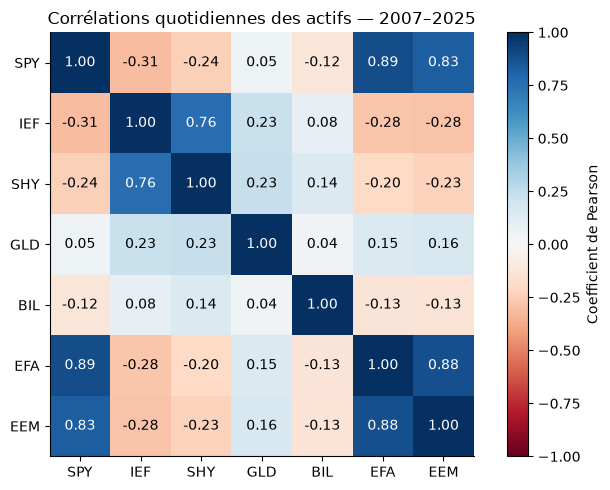

In [14]:
rendements_actifs = prix.pct_change(fill_method=None).iloc[1:]
correlations = rendements_actifs.corr()
tracer_correlations(correlations)

Les corrélations quotidiennes de SPY avec EFA et EEM sont élevées (**0,89** et **0,83**). Les marchés actions restent donc fortement liés. Avec GLD (**0,05**), IEF (**−0,31**) et BIL (**−0,12**), les mouvements sont différents, sans promettre une compensation à chaque chute.

### Comparer les mois selon l'inflation

On compose les rendements quotidiens en rendements mensuels, puis on les rapproche de l'inflation annuelle du même mois. On sépare les mois d'inflation **inférieure à 3 %** des autres. Ce seuil arrondi sert de repère descriptif ; on ne l'optimise pas sur les résultats.

On regarde aussi les années 2008 et 2022 pour illustrer le contraste entre obligations et trésorerie.

In [15]:
display(contexte_inflation(rendements_actifs, inflation).round(2))
annuel_actifs = 100 * ((1 + rendements_actifs).groupby(rendements_actifs.index.year).prod() - 1)
display(annuel_actifs.loc[[2008, 2022], ["SPY", "IEF", "SHY", "BIL"]].round(2))

,nombre de mois,corrélation mensuelle SPY–IEF
inflation < 3 %,160,-0.29
inflation ≥ 3 %,62,0.25


Ticker,SPY,IEF,SHY,BIL
Date,,,,
2008,-36.80,17.92,6.62,1.59
2022,-18.18,-15.16,-3.88,1.40


La corrélation mensuelle SPY–IEF est de **−0,29** dans les **160 mois** d'inflation inférieure à 3 %, contre **+0,25** dans les **62 autres**. Dans le second groupe, les mouvements vont davantage dans le même sens. Octobre 2025 est exclu de cette seule comparaison. Ces coefficients mensuels ne se comparent pas directement aux corrélations quotidiennes précédentes.

En 2008, IEF gagne **17,92 %** alors que SPY perd **36,80 %**. En 2022, ils perdent respectivement **15,16 %** et **18,18 %** ; SHY recule de **3,88 %**, tandis que BIL gagne **1,40 %** sur l'année entière.

Quand de nouvelles obligations offrent des taux plus élevés, les anciennes à taux fixe deviennent moins attractives et leur prix peut baisser. Les titres à échéance longue sont généralement plus sensibles à ce mouvement, et les intérêts reçus ne compensent pas toujours la baisse.

Ces résultats sont cohérents avec ce mécanisme, mais les groupes couvrent des chocs et périodes différents : on ne peut pas attribuer leurs écarts à la seule inflation. Celle-ci est publiée avec retard et peut être révisée ; on l'utilise pour décrire l'historique, pas pour fixer les poids à l'avance.

## 6. Robustesse : les constats dépendent-ils de nos choix ?

On modifie trois conventions sans retenir après coup la variante la plus favorable.

**Rééquilibrer annuellement.** Avec un retour aux poids cibles une fois par an, le recul maximal du US 60/40 passe de **−32,58 %** à **−29,61 %**. Les cinq allocations mixtes restent moins touchées que SPY. Le constat ne repose donc pas uniquement sur la fréquence mensuelle, sans prouver que la fréquence annuelle serait toujours préférable.

In [16]:
rendements_annuels = simuler_allocations(prix, "Y")
capital_annuel, recul_annuel = capital_et_recul(rendements_annuels, prix.index[0])
display(pd.DataFrame({"mensuel (%)": 100 * recul.min(),
                      "annuel (%)": 100 * recul_annuel.min()}).round(2))

,mensuel (%),annuel (%)
Actions US,-55.19,-55.19
Actions monde,-57.22,-57.28
US 60/40,-32.58,-29.61
Monde 60/40,-34.66,-31.54
US 50/30/20,-27.00,-24.34
US 60/40 court,-35.29,-33.22
US 60/40 cash,-36.85,-35.15


**Séparer les sous-périodes.** On recalcule l'écart moyen « portefeuille moins SPY » sur les jours où SPY baisse, avant puis après 2016. Un écart positif signifie que le portefeuille perd moins en moyenne.

Pour les actions monde, on passe de **−0,08** à **+0,04 point de pourcentage** par séance sélectionnée. Leur protection est donc meilleure dans la seconde partie de l'historique, ce que la moyenne globale masquait. Le tableau affiche des points de pourcentage, sans annualisation.

In [17]:
# la fonction renvoie des points de base qu'on convertit en points de pourcentage
comparaison_periodes = comparer_decennies(rendements) / 100
comparaison_periodes.columns = ["2007–2015 (points)", "2016–2025 (points)"]
display(comparaison_periodes.round(2))

,2007–2015 (points),2016–2025 (points)
Actions US,0.00,0.00
Actions monde,-0.08,0.04
US 60/40,0.46,0.32
Monde 60/40,0.41,0.35
US 50/30/20,0.52,0.40
US 60/40 court,0.40,0.31
US 60/40 cash,0.38,0.31


**Retenir un recul minimal de 20 %.** On garde alors trois des sept cycles initiaux. Les cinq allocations mixtes font mieux que SPY dans les trois, mais restent perdantes. On retrouve l'atténuation des pertes avec des baisses plus fortes. Ces épisodes faisaient déjà partie des sept : ce ne sont pas de nouvelles observations indépendantes.

In [18]:
display(comparer_seuils(capital))

cycles  cycles mieux que SPY  cycles sans perte
seuil (%) portefeuille                                                   
10.0      Actions US           7                     0                  0
          Actions monde        7                     3                  0
          US 60/40             7                     7                  0
          Monde 60/40          7                     7                  0
          US 50/30/20          7                     7                  0
          US 60/40 court       7                     7                  0
          US 60/40 cash        7                     7                  0
20.0      Actions US           3                     0                  0
          Actions monde        3                     1                  0
          US 60/40             3                     3                  0
          Monde 60/40          3                     3                  0
          US 50/30/20          3                     3                  0
          US 60/40 court       3                     3                  0
          US 60/40 cash        3                     3                  0

## 7. Réponse et limites

Au terme de l'étude, on voit que diversifier ne suffit pas à éviter les pertes. Ajouter des pays n'a pas protégé régulièrement pendant les baisses de SPY. En revanche, les portefeuilles qui associent actions et autres classes d'actifs ont mieux traversé les sept cycles retenus, même s'ils ont tous perdu de la valeur.

Le témoin aide à comprendre ce résultat : détenir moins d'actions atténue déjà les baisses. Les obligations peuvent apporter une protection supplémentaire, comme en 2008, mais leur contribution n'est pas toujours favorable. En 2022, les titres très courts représentés par BIL ont mieux résisté que les obligations à plus longue échéance.

On reste prudent : on étudie sept ETF encore existants, des poids illustratifs et environ 18,5 ans d'historique. Les rendements sont en dollars, sans correction de l'inflation ni conversion en euros. On utilise une source pour les cours, Yahoo Finance, et FRED pour l'inflation ; on ne confronte pas les prix à un second fournisseur. Enfin, le 50/30/20 change plusieurs expositions à la fois et les groupes d'inflation ne démontrent pas de causalité.

On retient donc une protection **partielle et variable**, qui dépend des actifs choisis et du type de baisse observé. Cela aide à comprendre les crises passées, sans permettre de prévoir la prochaine.